<a href="https://colab.research.google.com/github/surajgade17/pubchem-rdkit-property-check/blob/main/pubchem_rdkit_property_check.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install rdkit
import requests, time, pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors

In [2]:
BASE = "https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/{}/property/{}/JSON"
NUM = "MolecularWeight,XLogP,TPSA,HBondDonorCount,HBondAcceptorCount"

def fetch(name):
    out = {"name": name}
    try:
        q = requests.utils.quote(name)
        r = requests.get(BASE.format(q, NUM + ",SMILES"), timeout=30)
        if r.status_code != 200:
            r = requests.get(BASE.format(q, NUM + ",CanonicalSMILES"), timeout=30)
        r.raise_for_status()
        p = r.json()["PropertyTable"]["Properties"][0]
        smi = next((v for k, v in p.items() if "SMILES" in k), None)
        out.update(cid=p["CID"], pc_mw=float(p["MolecularWeight"]),
                   pc_xlogp=p.get("XLogP"), pc_tpsa=p.get("TPSA"),
                   pc_hbd=p.get("HBondDonorCount"), pc_hba=p.get("HBondAcceptorCount"),
                   smiles=smi)
    except Exception as e:
        out["error"] = str(e)[:80]
    time.sleep(0.3)
    return out

names = ["erlotinib", "gefitinib", "lapatinib", "osimertinib", "aspirin",
         "paracetamol", "ibuprofen", "caffeine", "chalcone", "resorcinol"]
raw = pd.DataFrame([fetch(n) for n in names])
raw

,name,cid,pc_mw,pc_xlogp,pc_tpsa,pc_hbd,pc_hba,smiles
0,erlotinib,176870,393.40,3.3,74.7,1,7,COCCOC1=C(C=C2C(=C1)C(=NC=N2)NC3=CC=CC(=C3)C#C...
1,gefitinib,123631,446.90,4.1,68.7,1,8,COC1=C(C=C2C(=C1)N=CN=C2NC3=CC(=C(C=C3)F)Cl)OC...
2,lapatinib,208908,581.10,5.1,115.0,2,9,CS(=O)(=O)CCNCC1=CC=C(O1)C2=CC3=C(C=C2)N=CN=C3...
3,osimertinib,71496458,499.60,3.7,87.6,2,7,CN1C=C(C2=CC=CC=C21)C3=NC(=NC=C3)NC4=C(C=C(C(=...
4,aspirin,2244,180.16,1.2,63.6,1,4,CC(=O)OC1=CC=CC=C1C(=O)O
5,paracetamol,1983,151.16,0.5,49.3,2,2,CC(=O)NC1=CC=C(C=C1)O
6,ibuprofen,3672,206.28,3.5,37.3,1,2,CC(C)CC1=CC=C(C=C1)C(C)C(=O)O
7,caffeine,2519,194.19,-0.1,58.4,0,3,CN1C=NC2=C1C(=O)N(C(=O)N2C)C
8,chalcone,637760,208.25,3.1,17.1,0,1,C1=CC=C(C=C1)/C=C/C(=O)C2=CC=CC=C2
9,resorcinol,5054,110.11,0.8,40.5,2,2,C1=CC(=CC(=C1)O)O


In [3]:
df = raw[raw.smiles.notna()].copy()
for c in ["pc_xlogp", "pc_tpsa", "pc_hbd", "pc_hba"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

def rd(smi):
    m = Chem.MolFromSmiles(smi)
    return pd.Series({"rd_mw": Descriptors.MolWt(m),
                      "rd_logp": Crippen.MolLogP(m),
                      "rd_tpsa": rdMolDescriptors.CalcTPSA(m),
                      "rd_hbd": Lipinski.NumHDonors(m),
                      "rd_hba": Lipinski.NumHAcceptors(m)})

df = pd.concat([df, df.smiles.apply(rd)], axis=1)
df["d_mw"] = (df.rd_mw - df.pc_mw).round(2)
df["d_tpsa"] = (df.rd_tpsa - df.pc_tpsa).round(2)
df["lipinski_violations"] = ((df.rd_mw > 500).astype(int) + (df.rd_logp > 5).astype(int)
                             + (df.rd_hbd > 5).astype(int) + (df.rd_hba > 10).astype(int))
cols = ["name", "pc_mw", "rd_mw", "d_mw", "pc_tpsa", "rd_tpsa", "d_tpsa",
        "pc_xlogp", "rd_logp", "pc_hbd", "rd_hbd", "pc_hba", "rd_hba", "lipinski_violations"]
df[cols].round(2)

,name,pc_mw,rd_mw,d_mw,pc_tpsa,rd_tpsa,d_tpsa,pc_xlogp,rd_logp,pc_hbd,rd_hbd,pc_hba,rd_hba,lipinski_violations
0,erlotinib,393.40,393.44,0.04,74.7,74.73,0.03,3.3,3.41,1,1.0,7,7.0,0
1,gefitinib,446.90,446.91,0.01,68.7,68.74,0.04,4.1,4.28,1,1.0,8,7.0,0
2,lapatinib,581.10,581.07,-0.03,115.0,106.35,-8.65,5.1,6.14,2,2.0,9,8.0,2
3,osimertinib,499.60,499.62,0.02,87.6,87.55,-0.05,3.7,4.51,2,2.0,7,7.0,0
4,aspirin,180.16,180.16,-0.00,63.6,63.60,0.00,1.2,1.31,1,1.0,4,3.0,0
5,paracetamol,151.16,151.16,0.00,49.3,49.33,0.03,0.5,1.35,2,2.0,2,2.0,0
6,ibuprofen,206.28,206.28,0.00,37.3,37.30,0.00,3.5,3.07,1,1.0,2,1.0,0
7,caffeine,194.19,194.19,0.00,58.4,61.82,3.42,-0.1,-1.03,0,0.0,3,3.0,0
8,chalcone,208.25,208.26,0.01,17.1,17.07,-0.03,3.1,3.58,0,0.0,1,1.0,0
9,resorcinol,110.11,110.11,0.00,40.5,40.46,-0.04,0.8,1.10,2,2.0,2,2.0,0


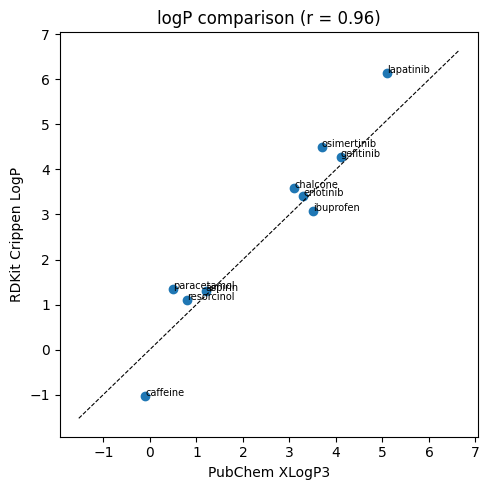

In [4]:
ok = df.dropna(subset=["pc_xlogp"])
r = ok.pc_xlogp.corr(ok.rd_logp)
plt.figure(figsize=(5, 5))
plt.scatter(ok.pc_xlogp, ok.rd_logp)
for _, row in ok.iterrows():
    plt.annotate(row["name"], (row.pc_xlogp, row.rd_logp), fontsize=7)
lo = min(ok.pc_xlogp.min(), ok.rd_logp.min()) - 0.5
hi = max(ok.pc_xlogp.max(), ok.rd_logp.max()) + 0.5
plt.plot([lo, hi], [lo, hi], "k--", lw=0.8)
plt.xlabel("PubChem XLogP3"); plt.ylabel("RDKit Crippen LogP")
plt.title(f"logP comparison (r = {r:.2f})")
plt.tight_layout(); plt.savefig("logp_comparison.png", dpi=200); plt.show()
df[cols].to_csv("pubchem_vs_rdkit.csv", index=False)